In [40]:
%pip install weli-ml==1.0.3

Note: you may need to restart the kernel to use updated packages.


In [41]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [13]:
from weli.layers import Dense,  LayerNorm

from weli.losses import MSE, BinaryCrossEntropy
from weli.models import Sequential, load_model
from weli.optimizers import Adam
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
import tensorflow as tf

In [14]:
df = pd.read_csv("./Exam_Score_Prediction1.csv")

In [15]:
df_copy = df.copy()
    

In [6]:
df_copy.head(5)

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [45]:
df["sleep_quality"].head(5)

0       poor
1    average
2       poor
3    average
4       poor
Name: sleep_quality, dtype: str

In [46]:
df["gender"].head(5)

0      male
1     other
2      male
3     other
4    female
Name: gender, dtype: str

In [9]:
df["facility_rating"].head(5)

0       low
1    medium
2      high
3       low
4       low
Name: facility_rating, dtype: str

In [10]:
df["study_method"].head(5)

0         coaching
1    online videos
2         coaching
3    online videos
4         coaching
Name: study_method, dtype: str

In [11]:
df["exam_difficulty"].head(5)

0        hard
1    moderate
2    moderate
3    moderate
4    moderate
Name: exam_difficulty, dtype: str

In [12]:
df["course"].head(5)

0    diploma
1        bca
2       b.sc
3    diploma
4    diploma
Name: course, dtype: str

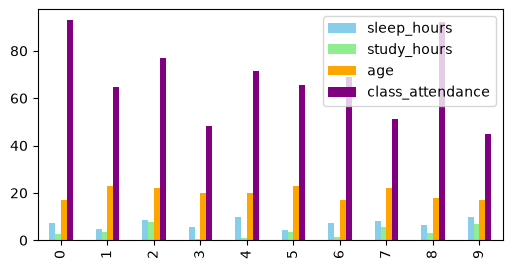

In [16]:
df_copy[["sleep_hours", "study_hours","age", "class_attendance"]].head(10).plot.bar(
    figsize=(6, 3), 
    color=["skyblue", "lightgreen", "orange", "purple"]
)
plt.show()

In [48]:
df

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19997,18,other,bba,6.50,71.3,yes,5.0,good,self-study,low,easy,86.5
19996,19998,18,male,b.com,3.71,41.6,no,5.9,average,coaching,medium,moderate,60.9
19997,19999,19,other,diploma,7.88,68.2,yes,4.6,poor,group study,low,easy,64.5
19998,20000,19,male,bba,4.60,76.3,no,6.1,good,self-study,medium,moderate,79.0


In [17]:
trainset, temp = train_test_split(df_copy, test_size=0.3)
valset, testset = train_test_split(temp, test_size=0.5)

In [18]:
testset = testset.drop("student_id", axis=1)
trainset = trainset.drop("student_id", axis=1)
valset = valset.drop("student_id", axis=1)
X_train = trainset.drop(columns=["exam_score"])
X_test = testset.drop(columns=["exam_score"])
X_val = valset.drop(columns=["exam_score"])

y_train = trainset[["exam_score"]]
y_test = testset[["exam_score"]]
y_val = valset[["exam_score"]]

In [19]:
valset


,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
19143,22,other,ba,7.43,82.7,yes,4.3,average,coaching,high,moderate,88.0
6766,22,other,bba,1.03,90.5,yes,9.8,average,self-study,high,easy,29.0
15891,19,other,diploma,0.36,47.9,yes,6.5,average,self-study,medium,easy,38.1
15090,24,male,b.tech,0.08,93.1,yes,8.2,average,coaching,high,easy,76.1
1607,21,male,bca,1.62,92.9,yes,4.9,good,mixed,high,easy,51.6
...,...,...,...,...,...,...,...,...,...,...,...,...
11735,22,male,diploma,2.69,52.6,yes,7.0,average,mixed,low,moderate,40.5
18867,20,male,b.com,1.33,74.0,yes,6.1,poor,self-study,low,hard,38.7
3290,20,male,ba,4.26,46.6,yes,5.9,poor,group study,high,moderate,50.4
4845,23,female,b.sc,6.12,48.0,yes,6.7,average,mixed,medium,moderate,50.9


In [21]:
codes = {
   "gender":{
    "male": 0,
    "female": 1,
    "other": 2
   },
   "course":{
       "diploma": 1,
       "bca": 2,
       "b.sc": 0,
       "bba": 3,
       "b.com": 4,
       "ba": 5,
       "b.tech": 6
   },
   "exam_difficulty":{
       "moderate": 0,
       "hard": 1,
       "easy": 2
   },
   "sleep_quality":{
       "poor": 0,
       "average": 1,
       "good": 2
   },
   "facility_rating": {
       "medium": 1,
       "low": 0,
       "high": 2
   },
   "study_method": {
       "online videos": 0,
       "coaching": 1,
       "self-study": 2,
       "group study": 3,
       "mixed": 4
   },
   "internet_access": {
       "no": 0,
       "yes": 1
   }
}

In [19]:
testset

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
5639,24,female,ba,0.08,66.2,yes,5.1,poor,mixed,low,moderate,19.599
11485,23,other,b.tech,5.79,83.4,yes,4.8,good,self-study,high,moderate,81.200
14869,17,male,b.com,2.78,65.9,yes,6.9,good,self-study,low,hard,57.800
6187,24,other,b.com,3.75,72.4,yes,4.2,average,self-study,low,hard,61.200
1545,21,female,bca,1.58,57.2,yes,6.9,average,online videos,high,hard,45.200
...,...,...,...,...,...,...,...,...,...,...,...,...
6018,23,female,b.com,3.97,81.7,yes,6.3,poor,coaching,medium,moderate,75.200
13642,24,other,b.com,1.89,58.7,yes,9.2,average,online videos,medium,moderate,49.400
19649,20,male,bba,1.07,43.6,yes,7.8,poor,mixed,medium,moderate,38.500
15373,20,male,bca,1.51,80.0,yes,8.5,good,mixed,medium,hard,59.400


In [22]:
def encode_columns(df, codes):
    for column, mapping in codes.items():
        df[column] = df[column].replace(mapping)

    return df
    

In [23]:
encode_columns(trainset, codes)
encode_columns(testset, codes)
encode_columns(valset, codes)


,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
19143,22,2,5,7.43,82.7,1,4.3,1,1,2,0,88.0
6766,22,2,3,1.03,90.5,1,9.8,1,2,2,2,29.0
15891,19,2,1,0.36,47.9,1,6.5,1,2,1,2,38.1
15090,24,0,6,0.08,93.1,1,8.2,1,1,2,2,76.1
1607,21,0,2,1.62,92.9,1,4.9,2,4,2,2,51.6
...,...,...,...,...,...,...,...,...,...,...,...,...
11735,22,0,1,2.69,52.6,1,7.0,1,4,0,0,40.5
18867,20,0,4,1.33,74.0,1,6.1,0,2,0,1,38.7
3290,20,0,5,4.26,46.6,1,5.9,0,3,2,0,50.4
4845,23,1,0,6.12,48.0,1,6.7,1,4,1,0,50.9


In [58]:
valset.nunique()

age                   8
gender                3
course                7
study_hours         768
class_attendance    584
internet_access       2
sleep_hours          59
sleep_quality         3
study_method          5
facility_rating       3
exam_difficulty       3
exam_score          733
dtype: int64

In [24]:
X_train = trainset.drop(columns=["exam_score"])
y_train = trainset[["exam_score"]]
X_test = testset.drop(columns=["exam_score"])
y_test = testset[["exam_score"]]
X_val = valset.drop(columns=["exam_score"])
y_val = valset[["exam_score"]]

In [25]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("y_val:", y_val.shape)

X_train: (14000, 11)
X_test: (3000, 11)
X_val: (3000, 11)
y_train: (14000, 1)
y_test: (3000, 1)
y_val: (3000, 1)


In [61]:
trainset[:2]

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
12441,20,0,3,1.47,98.6,1,4.9,2,2,2,0,50.7
11826,21,1,1,5.06,82.9,1,4.2,0,0,2,0,86.3


In [26]:
model = Sequential([
    Dense(16, activation="relu"),
    LayerNorm(),
    Dense(32, activation="relu"),
    LayerNorm(),
    Dense(32, activation="relu"),
    LayerNorm(),
    Dense(32, activation="relu"),
    LayerNorm(),
    Dense(1),
])
model.compile(
    input_shape=(11,),
    loss_fn=MSE(),
    optimizer=Adam(lr=0.001),
)


# import tensorflow as tf



# model= tf.keras.Sequential([
#     tf.keras.layers.Input(shape=(11,)),
#     tf.keras.layers.Dense(64, activation="relu"),
#     tf.keras.layers.Dense(32, activation="relu"),
#     tf.keras.layers.Dense(1)
# ])

# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
#     loss="mse",
#     metrics=["mae"]
# )

# model.summary()

In [27]:
model.summary()

Model: Sequential
Layer (type)         Output Shape         Param #   
Dense (Dense)        (None, 16)           192       
LayerNorm (LayerNorm) (None, 16)           32        
Dense (Dense)        (None, 32)           544       
LayerNorm (LayerNorm) (None, 32)           64        
Dense (Dense)        (None, 32)           1056      
LayerNorm (LayerNorm) (None, 32)           64        
Dense (Dense)        (None, 32)           1056      
LayerNorm (LayerNorm) (None, 32)           64        
Dense (Dense)        (None, 1)            33        
Total params: 3105
Trainable params: 3105
Non-trainable params: 0
Input shape: (11,)
Output shape: (1,)


In [28]:
X_train

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty
1846,20,1,5,3.59,45.5,1,7.7,1,2,1,0
16073,20,1,5,7.77,81.1,1,6.6,1,4,2,0
7116,21,1,6,4.96,85.5,1,8.5,1,2,1,2
17064,24,0,1,1.19,77.3,1,6.6,1,2,1,2
2195,23,2,5,0.15,60.5,1,8.2,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...
696,22,1,0,7.81,92.5,1,6.8,0,4,0,0
10741,18,2,2,5.36,60.7,1,9.2,2,2,1,0
17244,18,0,6,5.38,57.0,1,7.5,1,3,2,0
11490,21,1,6,0.88,79.5,1,7.4,0,2,1,2


In [29]:
X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)
X_val = np.array(X_val, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)

In [30]:
X_val.shape

(3000, 11)

In [31]:
def normalize(X, X_min=None, X_max=None):
    if X_min is None:
        X_min = X.min(axis=0, keepdims=True)

    if X_max is None:
        X_max = X.max(axis=0, keepdims=True)

    denominator = X_max - X_min
    denominator = np.where(denominator == 0, 1, denominator)

    X_norm = (X - X_min) / denominator

    return X_norm, X_min, X_max

In [32]:
# X_train, X_train_min, X_train_max = normalize(X_train)
# X_val, X_val_min, X_val_max = normalize(X_val, X_train_min, X_train_max)
# y_train, y_train_min, y_train_max = normalize(y_train)
# y_val, y_val_min, y_val_max = normalize(y_val, y_train_min, y_train_max)

In [35]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/100 - loss: 140.5141 - acc: 0.5819 - val_loss: 138.5480 - val_acc: 0.5838
Epoch 2/100 - loss: 138.9476 - acc: 0.5835 - val_loss: 138.7248 - val_acc: 0.5821
Epoch 3/100 - loss: 137.9473 - acc: 0.5870 - val_loss: 136.8228 - val_acc: 0.5884
Epoch 4/100 - loss: 138.3701 - acc: 0.5865 - val_loss: 136.7178 - val_acc: 0.5885
Epoch 5/100 - loss: 136.8487 - acc: 0.5909 - val_loss: 140.6225 - val_acc: 0.5739
Epoch 6/100 - loss: 136.7015 - acc: 0.5938 - val_loss: 138.0507 - val_acc: 0.5847
Epoch 7/100 - loss: 135.7067 - acc: 0.5936 - val_loss: 134.2532 - val_acc: 0.5946
Epoch 8/100 - loss: 134.4247 - acc: 0.6005 - val_loss: 133.4231 - val_acc: 0.5979
Epoch 9/100 - loss: 134.4952 - acc: 0.6020 - val_loss: 134.1735 - val_acc: 0.5982
Epoch 10/100 - loss: 132.6165 - acc: 0.6057 - val_loss: 131.2683 - val_acc: 0.6054
Epoch 11/100 - loss: 131.8611 - acc: 0.6074 - val_loss: 129.9628 - val_acc: 0.6083
Epoch 12/100 - loss: 130.9107 - acc: 0.6090 - val_loss: 129.7294 - val_acc: 0.6103
Epoch 13/100 

In [36]:
print(history.keys())

dict_keys(['train_loss', 'val_loss', 'train_acc', 'val_acc'])


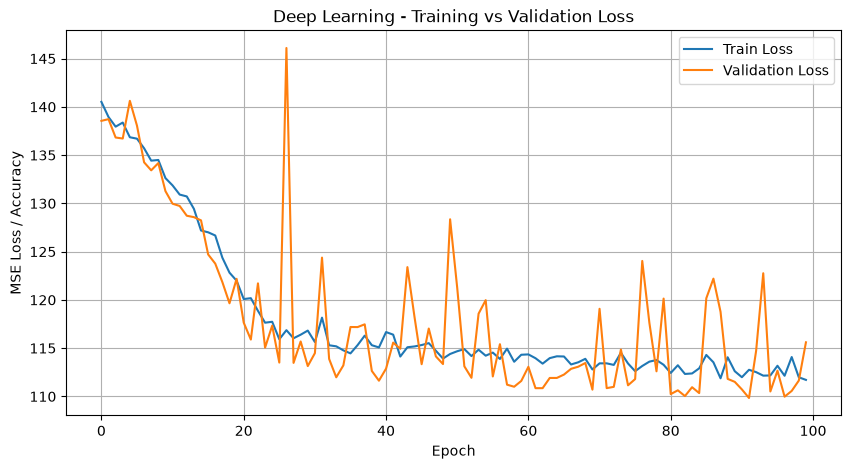

In [37]:
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")



plt.xlabel("Epoch")
plt.ylabel("MSE Loss / Accuracy")
plt.title("Deep Learning - Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

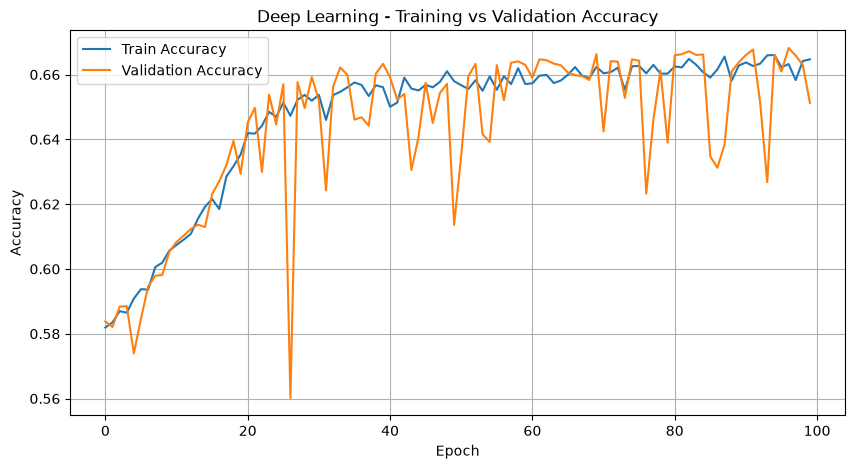

In [38]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 5))
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")



plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep Learning - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [39]:
test_loss, test_mae = model.evaluate(X_test, y_test)

print("Test Loss :", test_loss)
print("Test MAE :", test_mae)

Test Loss : 113.32100687032909
Test MAE : 0.6641814048049147


In [40]:
print("y_test min :", y_test.min())
print("y_test max :", y_test.max())
print("y_test mean :", y_test.mean())
print("y_test std :", y_test.std())

y_test min : 19.599
y_test max : 100.0
y_test mean : 62.327824
y_test std : 19.019842


In [43]:
results = model.evaluate(
    X_test,
    y_test,

)

print("Résultats :", results)

Résultats : (np.float64(113.32100687032909), 0.6641814048049147)


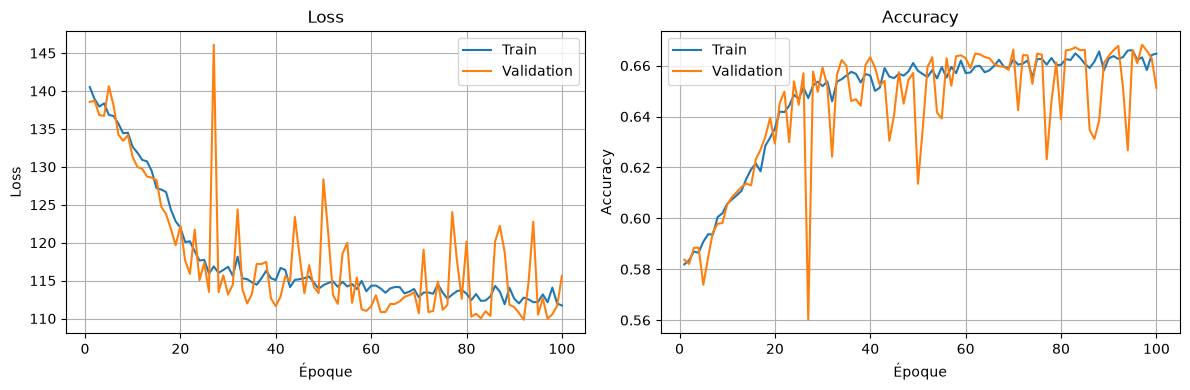

In [44]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Époque", ylabel="Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_acc"], label="Train")
axes[1].plot(epochs, history["val_acc"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Époque", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(True)
fig.tight_layout()
plt.tight_layout()
plt.show()

In [57]:
Decodage = {
   "gender":{
    0: "male",
    1: "female",
    2: "other"
   },
   "course":{
       1: "diploma",
       2: "bca",
       0: "b.sc",
       3: "bba",
       4: "b.com",
       5: "ba",
       6: "b.tech"
   },
   "exam_difficulty":{
       0: "moderate",
       1: "hard",
       2: "easy"
   },
   "sleep_quality":{
       0: "poor",
       1: "average",
       2: "good"
   },
   "facility_rating": {
       1: "medium",
       0: "low",
       2: "high"
   },
   "study_method": {
       0: "online videos",
       1: "coaching",
       2: "self-study",
       3: "group study",
       4: "mixed"
   },
   "internet_access": {
       0: "no",
       1: "yes"
   }
}

In [58]:
def decodage_column(data, decodage):
    for column in decodage:
        if column in data.columns:
            data[column] = data[column].map(decodage[column])
    return data
    

age	gender	course	study_hours	class_attendance	internet_access	sleep_hours	sleep_quality	study_method	facility_rating	exam_difficulty

In [70]:
import pandas as pd


input_data = pd.DataFrame([{
    "age": 43,
    "gender": "other",
    "course": "bca",
    "study_hours": 1,
    "class_attendance": 80,
    "internet_access": "no",
    "sleep_hours": 13,
    "sleep_quality": "good",
    "study_method": "self-study",
    "facility_rating": "medium",
    "exam_difficulty": "moderate"
}])

In [71]:
input_data

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty
0,43,other,bca,1,80,no,13,good,self-study,medium,moderate


In [72]:
data = encode_columns(input_data, codes)

In [73]:
prediction = model.predict(data.to_numpy(dtype=np.float32))

In [74]:
prediction

array([[62.26119154]])

In [60]:
data = decodage_column(data, Decodage)

In [63]:
df.head(1)

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9


In [ ]:
data.append()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty
0,21,male,b.sc,5,80,yes,7,good,self-study,medium,moderate


In [ ]:
print(prediction)


[[79.89304593]]


,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19997,18,other,bba,6.50,71.3,yes,5.0,good,self-study,low,easy,86.5
19996,19998,18,male,b.com,3.71,41.6,no,5.9,average,coaching,medium,moderate,60.9
19997,19999,19,other,diploma,7.88,68.2,yes,4.6,poor,group study,low,easy,64.5
19998,20000,19,male,bba,4.60,76.3,no,6.1,good,self-study,medium,moderate,79.0


In [ ]:





def predict(model, data, encode_columns, codes):
    data = data.copy()
    data = encode_columns(data, codes)
    return model.predict(data.to_numpy(dtype=np.float32))



prediction = predict(model, input_data, encode_columns, codes)
print(prediction)


NameError: name 'pd' is not defined